In [11]:
!pip install plotly -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from IPython.display import display

In [12]:
data = {
    "Movie": [
        "Avatar", "Titanic", "Avengers",
        "Joker", "Frozen", "Inception",
        "Interstellar", "The Batman",
        "Toy Story", "Iron Man",
        "Black Panther", "The Lion King",
        "Spider-Man", "Coco", "Dune",
        "Barbie", "Oppenheimer", "Jaws",
        "Up", "Gladiator"
    ],

    "Budget": [
        237, 200, 220, 55, 150,
        160, 165, 185, 30, 140,
        200, 260, 200, 175, 165,
        145, 100, 9, 175, 103
    ],

    "Revenue": [
        2923, 2264, 2798, 1074, 1290,
        829, 731, 772, 373, 585,
        1349, 1663, 921, 814, 407,
        1447, 975, 476, 735, 465
    ],

    "Rating": [
        7.9, 7.9, 8.4, 8.3, 7.4,
        8.8, 8.7, 7.8, 8.3, 7.9,
        7.3, 6.8, 8.2, 8.4, 8.0,
        6.8, 8.3, 8.1, 8.3, 8.5
    ],

    "Genre": [
        "Sci-Fi", "Romance", "Action",
        "Drama", "Animation", "Sci-Fi",
        "Sci-Fi", "Action", "Animation",
        "Action", "Action", "Animation",
        "Action", "Animation", "Sci-Fi",
        "Comedy", "Drama", "Thriller",
        "Animation", "Action"
    ],

    "Release_Date": pd.to_datetime([
        "2009-12-18", "1997-12-19",
        "2019-04-26", "2019-10-04",
        "2013-11-27", "2010-07-16",
        "2014-11-07", "2022-03-04",
        "1995-11-22", "2008-05-02",
        "2018-02-16", "2019-07-19",
        "2019-12-17", "2017-10-20",
        "2021-10-22", "2023-07-21",
        "2023-07-21", "1975-06-20",
        "2009-05-29", "2000-05-05"
    ])
}

df = pd.DataFrame(data)
display(df)

,Movie,Budget,Revenue,Rating,Genre,Release_Date
0,Avatar,237,2923,7.9,Sci-Fi,2009-12-18
1,Titanic,200,2264,7.9,Romance,1997-12-19
2,Avengers,220,2798,8.4,Action,2019-04-26
3,Joker,55,1074,8.3,Drama,2019-10-04
4,Frozen,150,1290,7.4,Animation,2013-11-27
5,Inception,160,829,8.8,Sci-Fi,2010-07-16
6,Interstellar,165,731,8.7,Sci-Fi,2014-11-07
7,The Batman,185,772,7.8,Action,2022-03-04
8,Toy Story,30,373,8.3,Animation,1995-11-22
9,Iron Man,140,585,7.9,Action,2008-05-02


In [13]:
# Checking number of rows and columns
print("Dataset Shape:")
print(df.shape)

# Checking columns name and data types
print("\nDataset Information:")
df.info()

# Statistical summary of numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

# Genre-wise movie count

print("\nGenre-wise Movie Count:")
print(df["Genre"].value_counts())


Dataset Shape:
(20, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Movie         20 non-null     object        
 1   Budget        20 non-null     int64         
 2   Revenue       20 non-null     int64         
 3   Rating        20 non-null     float64       
 4   Genre         20 non-null     object        
 5   Release_Date  20 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(2), object(2)
memory usage: 1.1+ KB

Descriptive Statistics:


,Budget,Revenue,Rating,Release_Date
count,20.000000,20.000000,20.000000,20
mean,153.700000,1144.550000,8.005000,2012-02-11 01:12:00
min,9.000000,373.000000,6.800000,1975-06-20 00:00:00
25%,130.750000,694.500000,7.875000,2009-02-20 00:00:00
50%,165.000000,875.000000,8.150000,2016-04-29 00:00:00
75%,200.000000,1373.500000,8.325000,2019-10-22 12:00:00
max,260.000000,2923.000000,8.800000,2023-07-21 00:00:00
std,66.078183,750.591589,0.557697,NaN



Genre-wise Movie Count:
Genre
Action       6
Animation    5
Sci-Fi       4
Drama        2
Romance      1
Comedy       1
Thriller     1
Name: count, dtype: int64


Correlation Matrix:


,Budget,Revenue,Rating
Budget,1.000000,0.603384,-0.320160
Revenue,0.603384,1.000000,-0.284814
Rating,-0.320160,-0.284814,1.000000


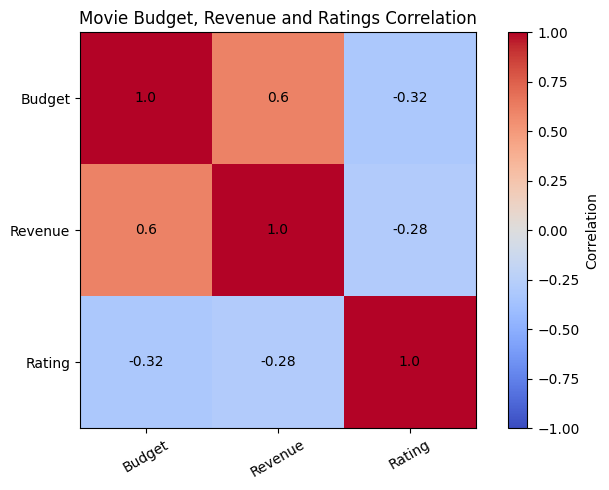

In [14]:
# Correlation
correlation = df[["Budget", "Revenue", "Rating"]].corr()
print("Correlation Matrix:")
display(correlation)

# Visualizing correlation using a heatmap
plt.figure(figsize=(7,5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=30)
plt.yticks(range(len(correlation.columns)), correlation.columns)

# Display correlation values
for i in range(len(correlation.columns)):
  for j in range(len(correlation.columns)):
    plt.text(j, i, round(correlation.iloc[i, j],2),
    ha="center",
    va="center"
    )
plt.title("Movie Budget, Revenue and Ratings Correlation")

plt.tight_layout()
plt.show()

In [15]:
# Group movies by genre
genre_summary = df.groupby("Genre").agg(
    Average_budget=("Budget", "mean"),
    Average_revenue=("Revenue", "mean"),
    Average_rating=("Rating", "mean"),
    Movie_count=("Movie", "count")
).round(2)

# Display genre-wise summary
print("Genre-wise Movie Analysis:")
display(genre_summary)

Genre-wise Movie Analysis:


,Average_budget,Average_revenue,Average_rating,Movie_count
Genre,,,,
Action,174.67,1148.33,8.02,6
Animation,158.00,975.00,7.84,5
Comedy,145.00,1447.00,6.80,1
Drama,77.50,1024.50,8.30,2
Romance,200.00,2264.00,7.90,1
Sci-Fi,181.75,1222.50,8.35,4
Thriller,9.00,476.00,8.10,1


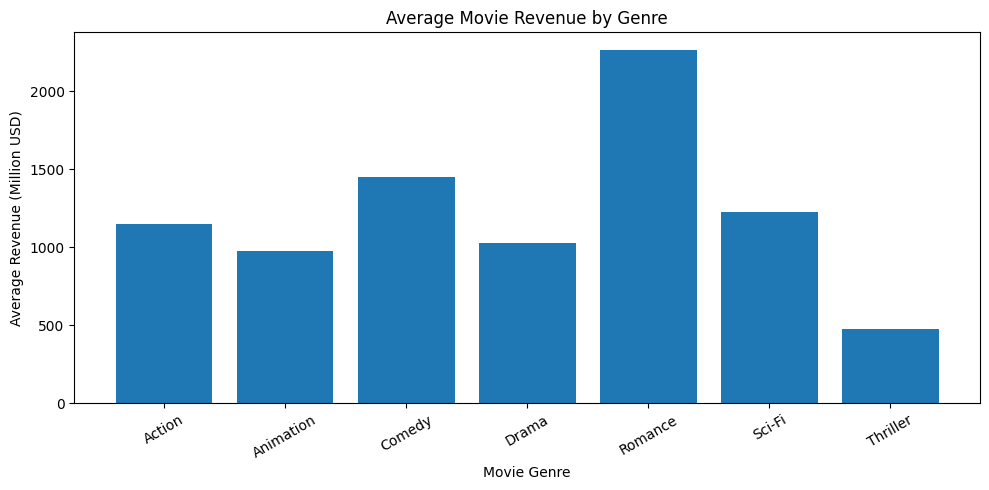

In [16]:
# Bar Chart: Average revenue by genre
plt.figure(figsize=(10,5))
plt.bar(
    genre_summary.index,
    genre_summary["Average_revenue"]
)
plt.title("Average Movie Revenue by Genre")
plt.xlabel("Movie Genre")
plt.ylabel("Average Revenue (Million USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**DASHBOARD**

In [17]:
# Creaitng 2x2 Dashboard
fig = make_subplots(
    rows=2,
    cols=2,

    subplot_titles=(
       "Higher Budgets Tend to Have Higher Revenues",
       "Average Revenue Varies Across Movie Genres",
       "Most Sample Movies Have Ratings Above 8",
       "Movie Revenues Across Release Dates"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

# Chart 1: Scatter Plot
fig.add_trace(

    go.Scatter(
        x=df["Budget"],
        y=df["Revenue"],

        mode="markers",
        text=df["Movie"],
        textposition="top center",
        marker=dict(
            size=10,
            color=df["Rating"],
            colorscale="Viridis",
            showscale=False,
            colorbar=dict(title="Rating")
        ),
        name="Movies",
        hovertemplate=
        "<b>%{text}</b><br>" +
        "Budget: $%{x} Million<br>" +
        "Revenue: $%{y} Million<br>" +
        "<extra></extra>"
    ),
    row=1,
    col=1
)

# Chart 2: Bar Chart
fig.add_trace(
    go.Bar(
        x=genre_summary.index,
        y=genre_summary["Average_revenue"],
        name="Average Revenue",
        hovertemplate=
        "Genre: %{x}<br>" +
        "Average Revenue: $%{y:.2f} Million" +
        "<extra></extra>"
    ),
    row=1,
    col=2
)

# Chart 3: Histogram
fig.add_trace(
    go.Histogram(
        x=df["Rating"],
        nbinsx=8,
        name="Movie Ratings",
        hovertemplate=
        "Rating: %{x}<br>" +
        "Number of Movies: %{y}" +
        "<extra></extra>"
    ),
    row=2,
    col=1
)

# Chart 4: Line Chart
date_summary = df.sort_values("Release_Date")
fig.add_trace(
    go.Scatter(
        x=date_summary["Release_Date"],
        y=date_summary["Revenue"],
        mode="lines+markers",
        text=date_summary["Movie"],
        name="Movie Revenue",
        hovertemplate=
        "<b>%{text}</b><br>" +
        "Release Date: %{x|%d %b %Y}<br>" +
        "Revenue: $%{y} Million" +
        "<extra></extra>"
    ),
    row=2,
    col=2
)

# Axis labels

fig.update_xaxes(title_text="Budget (Million USD)", row=1, col=1)
fig.update_yaxes(title_text="Revenue (Million USD)", row=1, col=1)

fig.update_xaxes(title_text="Genre", row=1, col=2)
fig.update_yaxes(title_text="Average Revenue (Million USD)", row=1, col=2)

fig.update_xaxes(title_text="Rating", row=2, col=1)
fig.update_yaxes(title_text="Number of Movies", row=2, col=1)

fig.update_xaxes(title_text="Release Date", row=2, col=2)
fig.update_yaxes(title_text="Revenue (Million USD)", row=2, col=2)


# Dashboard layout
fig.update_layout(
        title=dict(
        text="MOVIE & ENTERTAINMENT INDUSTRY ANALYTICS DASHBOARD",
        x=0.5,
        font=dict(size=20)
    ),
    height=900,
    width=1200,
    template="plotly_white",
    showlegend=True,
    hovermode="closest"
)


# Display dashboard
fig.show()

In [18]:
# Exporting Dashboard
fig.write_html(
    "Movie_Entertainment_Dashboard.html",
    include_plotlyjs=True
)
print("Dashboard Exported Successfully!")

Dashboard Exported Successfully!


In [19]:
from google.colab import files
files.download("Movie_Entertainment_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Project Reflection**

The Movie and Entertainment Industry Analytics Dashboard provides an overview of 20 movies based on their budget, revenue, ratings, genres, and release dates. The scatter plot helps understand the relationship between movie budgets and revenues. The bar chart compares average revenue across different movie genres, while the histogram shows the distribution of movie ratings. The line chart presents movie revenues according to their release dates. The correlation analysis and groupby analysis provide additional insights into movie performance. Overall, this dashboard helps identify patterns and trends in the movie entertainment industry. However, the dataset contains only 20 sample movie records, so the findings should not be generalized to the entire entertainment industry.